In [1]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
# Load the breast cancer dataset
df = pd.read_csv("../data/breast_cancer_wdbc.csv")

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset Shape: (569, 31)


,radius1,texture1,perimeter1,area1,smoothness1,compactness1,concavity1,concave_points1,symmetry1,fractal_dimension1,...,texture3,perimeter3,area3,smoothness3,compactness3,concavity3,concave_points3,symmetry3,fractal_dimension3,diagnosis
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,1
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,1
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,1
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,1
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,1


In [3]:
# Separate features and target
X = df.drop(columns=["diagnosis"])
y = df["diagnosis"]

print("Input Features:", X.shape)
print("Target Variable:", y.shape)

print("\nDiagnosis Distribution:")
print(y.value_counts())

Input Features: (569, 30)
Target Variable: (569,)

Diagnosis Distribution:
diagnosis
0    357
1    212
Name: count, dtype: int64


In [4]:
# Split dataset into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("Training Labels:", y_train.shape)
print("Testing Labels:", y_test.shape)

Training Features: (455, 30)
Testing Features: (114, 30)
Training Labels: (455,)
Testing Labels: (114,)


In [5]:
# Initialize StandardScaler
scaler = StandardScaler()

# Fit scaler using training data and transform it
X_train_scaled = scaler.fit_transform(X_train)

# Transform testing data using the same scaler
X_test_scaled = scaler.transform(X_test)

print("Feature Scaling Completed!")

print("Scaled Training Data:", X_train_scaled.shape)
print("Scaled Testing Data:", X_test_scaled.shape)

Feature Scaling Completed!
Scaled Training Data: (455, 30)
Scaled Testing Data: (114, 30)


In [6]:
# Convert scaled training data into DataFrame
X_train_scaled_df = pd.DataFrame(
    X_train_scaled,
    columns=X.columns
)

# Display first five scaled records
display(X_train_scaled_df.head())

# Check mean and standard deviation
print("\nFeature Means (first 5):")
print(X_train_scaled_df.mean().head().round(3))

print("\nFeature Standard Deviations (first 5):")
print(X_train_scaled_df.std().head().round(3))

,radius1,texture1,perimeter1,area1,smoothness1,compactness1,concavity1,concave_points1,symmetry1,fractal_dimension1,...,radius3,texture3,perimeter3,area3,smoothness3,compactness3,concavity3,concave_points3,symmetry3,fractal_dimension3
0,0.518559,0.891826,0.424632,0.383925,-0.974744,-0.689772,-0.688586,-0.398175,-1.039155,-0.825056,...,0.579798,1.313242,0.466908,0.445983,-0.596155,-0.634722,-0.610227,-0.235744,0.054566,0.021837
1,-0.516364,-1.639710,-0.541349,-0.542961,0.476219,-0.631834,-0.604281,-0.303075,0.521543,-0.454523,...,-0.582459,-1.690291,-0.611934,-0.587014,0.273582,-0.814844,-0.712666,-0.323208,-0.137576,-0.904402
2,-0.368118,0.455515,-0.388250,-0.402970,-1.432979,-0.383927,-0.342175,-0.765459,-0.850857,-0.226171,...,-0.398622,0.181977,-0.475431,-0.420778,-1.622785,-0.391399,-0.431313,-0.890825,-0.675893,-0.144016
3,0.205285,0.726168,0.400330,0.070612,0.243253,2.203585,2.256094,1.213233,0.818474,0.899791,...,-0.000309,0.274191,0.513776,-0.099482,0.418538,2.865970,2.958619,1.977064,-0.075646,1.728848
4,1.243005,0.194195,1.210377,1.206652,-0.111442,0.051348,0.732962,0.713767,-0.427187,-0.822184,...,1.012835,0.223144,0.938517,0.880910,0.073201,-0.277006,0.327775,0.501859,-0.909322,-0.546249



Feature Means (first 5):
radius1       -0.0
texture1       0.0
perimeter1     0.0
area1         -0.0
smoothness1    0.0
dtype: float64

Feature Standard Deviations (first 5):
radius1        1.001
texture1       1.001
perimeter1     1.001
area1          1.001
smoothness1    1.001
dtype: float64


In [7]:
# Check training class distribution
print("Training Class Distribution:")
print(y_train.value_counts())

print("\nTraining Class Percentages:")
print((y_train.value_counts(normalize=True) * 100).round(2))

# Check testing class distribution
print("\nTesting Class Distribution:")
print(y_test.value_counts())

print("\nTesting Class Percentages:")
print((y_test.value_counts(normalize=True) * 100).round(2))

Training Class Distribution:
diagnosis
0    285
1    170
Name: count, dtype: int64

Training Class Percentages:
diagnosis
0    62.64
1    37.36
Name: proportion, dtype: float64

Testing Class Distribution:
diagnosis
0    72
1    42
Name: count, dtype: int64

Testing Class Percentages:
diagnosis
0    63.16
1    36.84
Name: proportion, dtype: float64


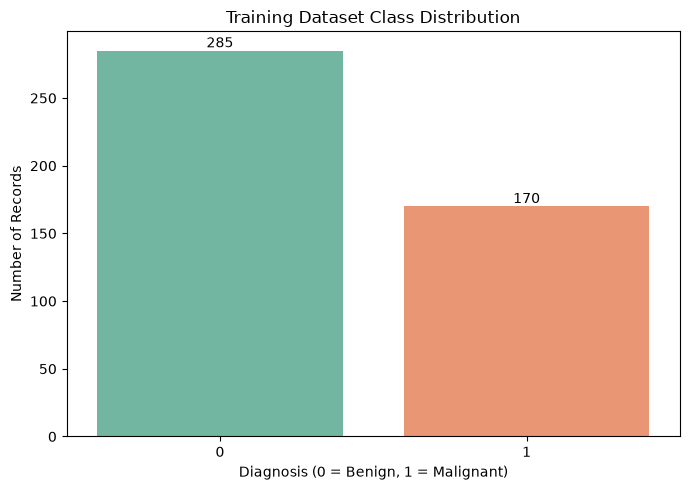

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(7, 5))

ax = sns.countplot(
    x=y_train,
    hue=y_train,
    palette="Set2",
    legend=False
)

plt.title("Training Dataset Class Distribution")
plt.xlabel("Diagnosis (0 = Benign, 1 = Malignant)")
plt.ylabel("Number of Records")

for container in ax.containers:
    ax.bar_label(container)

plt.tight_layout()
plt.show()

In [9]:
from sklearn.utils.class_weight import compute_class_weight

# Calculate class weights using training labels only
classes = np.unique(y_train)

weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train
)

class_weights = dict(zip(classes, weights))

print("Calculated Class Weights:")
print(class_weights)

Calculated Class Weights:
{np.int64(0): np.float64(0.7982456140350878), np.int64(1): np.float64(1.338235294117647)}


### Class Imbalance Analysis – Observation

The dataset contains 357 Benign cases (62.74%) and 212 Malignant cases (37.26%). Therefore, the dataset has a moderate class imbalance.

Stratified sampling was used during the train-test split to maintain similar class proportions in both datasets.

Class weights were calculated to investigate the effect of giving greater importance to the minority Malignant class during model training.

The original dataset distribution was preserved to avoid unnecessary information loss or changes to the training data.

In [10]:
print("Original Dataset:", df.shape)

print("\nTraining Dataset:", X_train.shape)
print("Testing Dataset:", X_test.shape)

print("\nTraining Labels:", y_train.shape)
print("Testing Labels:", y_test.shape)

print("\nScaled Training Dataset:", X_train_scaled.shape)
print("Scaled Testing Dataset:", X_test_scaled.shape)

Original Dataset: (569, 31)

Training Dataset: (455, 30)
Testing Dataset: (114, 30)

Training Labels: (455,)
Testing Labels: (114,)

Scaled Training Dataset: (455, 30)
Scaled Testing Dataset: (114, 30)


In [11]:
# Check whether training and testing indices overlap
overlapping_indices = set(X_train.index).intersection(
    set(X_test.index)
)

print("Overlapping Records:", len(overlapping_indices))

if len(overlapping_indices) == 0:
    print("No data leakage through train-test overlap.")
else:
    print("Warning: Overlapping records found!")

Overlapping Records: 0
No data leakage through train-test overlap.


In [12]:
# Check scaled training data statistics
print("Training Feature Means:")
print(np.round(X_train_scaled.mean(axis=0)[:5], 4))

print("\nTraining Feature Standard Deviations:")
print(np.round(X_train_scaled.std(axis=0)[:5], 4))

Training Feature Means:
[-0.  0.  0. -0.  0.]

Training Feature Standard Deviations:
[1. 1. 1. 1. 1.]


In [13]:
import os

os.makedirs("../data/processed", exist_ok=True)

print("Processed data folder created successfully!")

Processed data folder created successfully!


In [14]:
# Save unscaled training and testing features
X_train.to_csv("../data/processed/X_train.csv", index=False)
X_test.to_csv("../data/processed/X_test.csv", index=False)

# Save training and testing labels
y_train.to_csv("../data/processed/y_train.csv", index=False)
y_test.to_csv("../data/processed/y_test.csv", index=False)

print("Original train-test datasets saved successfully!")

Original train-test datasets saved successfully!


In [15]:
# Convert scaled arrays into DataFrames
X_train_scaled_df = pd.DataFrame(
    X_train_scaled,
    columns=X.columns
)

X_test_scaled_df = pd.DataFrame(
    X_test_scaled,
    columns=X.columns
)

# Save scaled datasets
X_train_scaled_df.to_csv(
    "../data/processed/X_train_scaled.csv",
    index=False
)

X_test_scaled_df.to_csv(
    "../data/processed/X_test_scaled.csv",
    index=False
)

print("Scaled datasets saved successfully!")

Scaled datasets saved successfully!


### Data Preprocessing – Final Observation

The dataset was separated into input features and the target variable. An 80:20 train-test split was performed using stratified sampling to maintain class proportions.

StandardScaler was applied to the numerical features. The scaler was fitted only on the training data and then used to transform the testing data, preventing data leakage.

The original and scaled datasets were saved separately for use in different machine learning algorithms.

The processed data is now ready for machine learning experiments.